# Ryan Kubanyi
## wk15 4/30/26
### Continued: Python Data Cleaning and Visualization Project

In [1]:
import numpy as np
import pandas as pd
from pandas import *
from numpy.random import random, randn, randint

import matplotlib as mpl
import matplotlib.pyplot as plt

%matplotlib inline

In [3]:
#Upload data from a csv file
data = pd.read_csv('AMZN-3.csv')

In [4]:
data.head(20)

,Date,Source,Open,High,Low,Close,Adj Close,Volume,Stock
0,1/3/2012,yahoo,175.889999,179.479996,175.550003,179.029999,179.029999,5110800,amazon
1,1/4/2012,yahoo,179.210007,180.500000,176.070007,177.509995,177.509995,4205200,amazon
2,1/5/2012,yahoo,175.940002,178.250000,174.050003,177.610001,177.610001,3809100,amazon
3,1/6/2012,yahoo,178.070007,184.649994,177.500000,182.610001,182.610001,7008400,amazon
4,1/9/2012,yahoo,182.759995,184.369995,177.000000,178.559998,178.559998,5056900,amazon
5,1/10/2012,yahoo,181.100006,182.399994,177.100006,179.339996,179.339996,3985800,amazon
6,1/11/2012,yahoo,179.639999,180.770004,178.190002,178.899994,178.899994,3102700,amazon
7,1/12/2012,yahoo,179.419998,179.490005,175.750000,175.929993,175.929993,5385800,amazon
8,1/13/2012,yahoo,175.809998,178.800003,173.500000,178.419998,178.419998,4753500,amazon
9,1/17/2012,yahoo,180.149994,183.300003,178.509995,181.660004,181.660004,5644500,amazon


In [5]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2242 entries, 0 to 2241
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   Date       2242 non-null   object 
 1   Source     2242 non-null   object 
 2   Open       2241 non-null   float64
 3   High       2240 non-null   float64
 4   Low        2242 non-null   float64
 5   Close      2239 non-null   float64
 6   Adj Close  2241 non-null   float64
 7   Volume     2242 non-null   int64  
 8   Stock      2242 non-null   object 
dtypes: float64(5), int64(1), object(3)
memory usage: 157.8+ KB


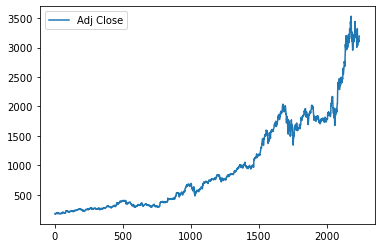

In [7]:
data['Adj Close'].plot(legend = True)

In [9]:
data.index

RangeIndex(start=0, stop=2242, step=1)

In [16]:
#Count the number of numerical and non-numerical columns
from pandas.api.types import is_numeric_dtype

n = 0
for c in data.columns:
    if is_numeric_dtype(data[c]):
        n+=1
        
n

6

In [17]:
len(data.columns)

9

In [19]:
# data cleaning
data.isnull().sum()

Date         0
Source       0
Open         1
High         2
Low          0
Close        3
Adj Close    1
Volume       0
Stock        0
dtype: int64

In [21]:
data.dropna(inplace=True)

In [22]:
data.isnull().sum()

Date         0
Source       0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
Stock        0
dtype: int64

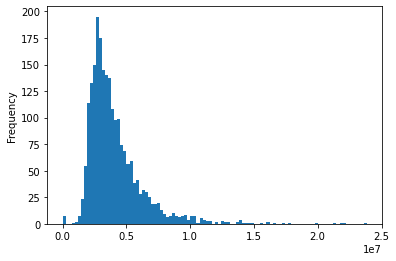

In [23]:
# clean absnormal values
data['Volume'].plot(kind='hist',bins=100)

In [24]:
data['Volume'].min()

0

In [26]:
data['Volume'].sort_values().head(20)

29            0
114           1
18            5
161           6
47           23
90           25
66           78
2007     881300
245      984400
1001    1091200
126     1331700
879     1343400
426     1350600
376     1373000
497     1380400
405     1415000
411     1422600
415     1457100
1164    1458800
403     1504500
Name: Volume, dtype: int64

In [28]:
data = data(data['Volume'] > 100000)

TypeError: 'DataFrame' object is not callable

In [29]:
data['Volume'].sort_values().head(20)

29            0
114           1
18            5
161           6
47           23
90           25
66           78
2007     881300
245      984400
1001    1091200
126     1331700
879     1343400
426     1350600
376     1373000
497     1380400
405     1415000
411     1422600
415     1457100
1164    1458800
403     1504500
Name: Volume, dtype: int64

In [30]:
data.head(20)

,Date,Source,Open,High,Low,Close,Adj Close,Volume,Stock
0,1/3/2012,yahoo,175.889999,179.479996,175.550003,179.029999,179.029999,5110800,amazon
1,1/4/2012,yahoo,179.210007,180.500000,176.070007,177.509995,177.509995,4205200,amazon
2,1/5/2012,yahoo,175.940002,178.250000,174.050003,177.610001,177.610001,3809100,amazon
3,1/6/2012,yahoo,178.070007,184.649994,177.500000,182.610001,182.610001,7008400,amazon
4,1/9/2012,yahoo,182.759995,184.369995,177.000000,178.559998,178.559998,5056900,amazon
5,1/10/2012,yahoo,181.100006,182.399994,177.100006,179.339996,179.339996,3985800,amazon
6,1/11/2012,yahoo,179.639999,180.770004,178.190002,178.899994,178.899994,3102700,amazon
7,1/12/2012,yahoo,179.419998,179.490005,175.750000,175.929993,175.929993,5385800,amazon
8,1/13/2012,yahoo,175.809998,178.800003,173.500000,178.419998,178.419998,4753500,amazon
9,1/17/2012,yahoo,180.149994,183.300003,178.509995,181.660004,181.660004,5644500,amazon


In [32]:
constant_columns=[]

for c in data.columns:
    n = len(data[c].unique())
    if n == 1:
        constant_columns.append(c)
        
constant_columns

['Source', 'Stock']

In [33]:
data.drop(columns=constant_columns, inplace=True,axis=1)

In [34]:
data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume'], dtype='object')

In [35]:
len(data.columns)

7

In [42]:
dateObject = pd.DatetimeIndex(data['Date'])
dateObject

DatetimeIndex(['2012-01-03', '2012-01-04', '2012-01-05', '2012-01-06',
               '2012-01-09', '2012-01-10', '2012-01-11', '2012-01-12',
               '2012-01-13', '2012-01-17',
               ...
               '2020-11-13', '2020-11-16', '2020-11-17', '2020-11-18',
               '2020-11-19', '2020-11-20', '2020-11-23', '2020-11-24',
               '2020-11-25', '2020-11-27'],
              dtype='datetime64[ns]', name='Date', length=2235, freq=None)

In [50]:
data['Day'] = dateObject.day
data['Month'] = dateObject.month
data['Year'] = dateObject.year

In [51]:
data

,Date,Open,High,Low,Close,Adj Close,Volume,Day,Month,Year
0,1/3/2012,175.889999,179.479996,175.550003,179.029999,179.029999,5110800,3,1,2012
1,1/4/2012,179.210007,180.500000,176.070007,177.509995,177.509995,4205200,4,1,2012
2,1/5/2012,175.940002,178.250000,174.050003,177.610001,177.610001,3809100,5,1,2012
3,1/6/2012,178.070007,184.649994,177.500000,182.610001,182.610001,7008400,6,1,2012
4,1/9/2012,182.759995,184.369995,177.000000,178.559998,178.559998,5056900,9,1,2012
...,...,...,...,...,...,...,...,...,...,...
2237,11/20/2020,3117.020020,3132.889893,3098.050049,3099.399902,3099.399902,3374400,20,11,2020
2238,11/23/2020,3116.699951,3139.750000,3065.459961,3098.389893,3098.389893,4708900,23,11,2020
2239,11/24/2020,3100.500000,3134.250000,3086.260010,3118.060059,3118.060059,3602100,24,11,2020
2240,11/25/2020,3141.870117,3198.000000,3140.260010,3185.070068,3185.070068,3790400,25,11,2020


In [52]:
data.columns

Index(['Date', 'Open', 'High', 'Low', 'Close', 'Adj Close', 'Volume', 'Day',
       'Month', 'Year'],
      dtype='object')

In [54]:
# Use visualization for data analysis
# Show the trend of the Stock's volume over the years

yearGroup = data[['Year', 'Volume']].groupby('Year')
yearGroup

Text(0, 0.5, "stock's Volume")

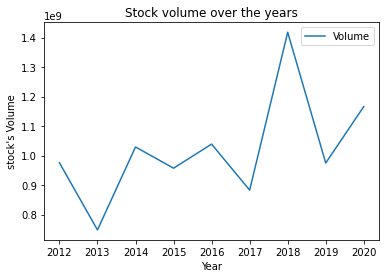

In [55]:
yearGroup.sum().plot(y='Volume', title="Stock volume over the years")
plt.ylabel("stock's Volume")

In [56]:
yearGroup.sum()

,Volume
Year,
2012,975492538
2013,747905700
2014,1029066700
2015,957102000
2016,1038756300
2017,882705400
2018,1417897600
2019,974729400
2020,1166035700


In [58]:
monthGroup = data[['Month', 'Volume']].groupby('Month')
monthGroup

In [60]:
monthGroup.mean().plot(y='Adj Close', title='Adj Close Over Months')
plt.ylabel('Adj Close Prices')

KeyError: 'Adj Close'

In [61]:
dayGroup = data[['Day', 'Volume']].groupby('Day')
dayGroup

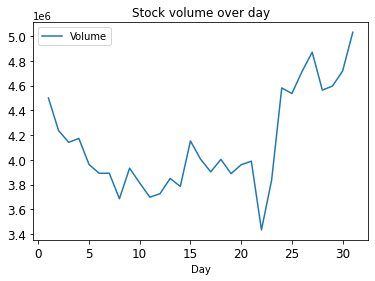

In [62]:
dayGroup.mean().plot(y='Volume', title="Stock volume over day", fontsize=12)